<a href="https://colab.research.google.com/github/MulkernHunter/INFO-4670/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Objective
**Goal:** Predict if a customer buys a car (1) or not (0) using Age and Salary. Logistic regression combines the features into a score and passes it through the sigmoid function, which turns it into a probability between 0 and 1.

**Why logistic regression:** The answer is yes or no, and logistic regression is made for binary outcomes. It gives a probability for each customer and is simple to interpret.

### Step 1: Import libraries and load data

In [1]:
# Name: Hunter Mulkern
import pandas as pd

df = pd.read_csv('car_purchase_data.csv')
df.head()

,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


### Step 2: Split features and target

In [4]:
# Name: Hunter Mulkern
X = df[['Age', 'Salary']]   # inputs
y = df['Purchased']         # answer we want to predict (1 = bought, 0 = didn't)

### Step 3: Train/Test Split

In [5]:
# Name: Hunter Mulkern
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Train rows: 300 | Test rows: 100


### Step 4: Feature Scaling

In [6]:
# Name: Hunter Mulkern
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn scaling from training data
X_test = scaler.transform(X_test)         # apply same scaling to test data

### Step 5: Train Logistic Regression Model

In [7]:
# Name: Hunter Mulkern
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

### Step 6: Predict and Evaluate

In [8]:
# Name: Hunter Mulkern
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.89
Confusion Matrix:
 [[65  3]
 [ 8 24]]
              precision    recall  f1-score   support

           0       0.89      0.96      0.92        68
           1       0.89      0.75      0.81        32

    accuracy                           0.89       100
   macro avg       0.89      0.85      0.87       100
weighted avg       0.89      0.89      0.89       100



### Step 7: Visualization of Decision Regions

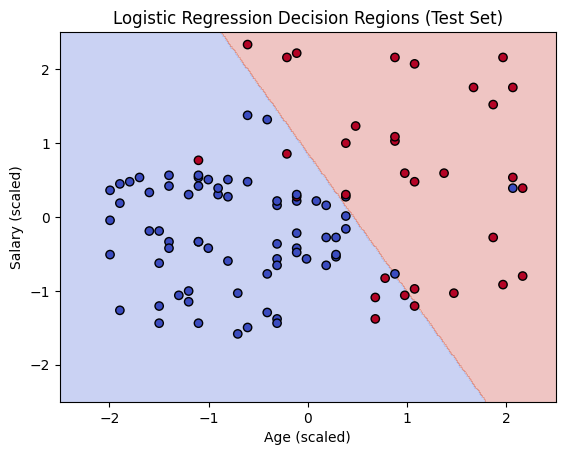

In [9]:
# Name: Hunter Mulkern
import numpy as np
import matplotlib.pyplot as plt

# Color every point on a grid by what the model predicts, then plot the real test customers
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 300), np.linspace(-2.5, 2.5, 300))
zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, zz, alpha=0.3, cmap='coolwarm')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', edgecolor='k')
plt.title('Logistic Regression Decision Regions (Test Set)')
plt.xlabel('Age (scaled)')
plt.ylabel('Salary (scaled)')
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

## Answers

**1. Why can probabilities be used for classification?**
The model outputs a probability of buying. We use a cutoff of 0.5: if the probability is 0.5 or higher, predict 1 (buys); otherwise predict 0. That cutoff is the line between the two colors in the plot.

**2. Which customers are more likely to buy?**
Older customers and customers with higher salaries. Age has the stronger effect. Young customers with low salaries are least likely to buy.

**3. What could cause low accuracy?**
- The model draws a straight line, but some buyers (older people with low salaries) don't fit that line.
- Only two features are used; other things affect buying decisions.
- More people didn't buy than did, so the model leans toward predicting "no."
- The dataset is small (400 rows), so results change with the random split.

**4. How could accuracy improve?**
- Add features such as Gender (encoded as 0/1) or Age × Salary.
- Use cross-validation and tune the model's settings (like `C`).
- Try other models such as k-NN, SVM, or random forest.

## Results Discussion
The model reached **89% accuracy** on the test set, which meets the 87.5% requirement. It predicts non-buyers very well, but misses some actual buyers (8 of 32), mostly older customers with lower salaries.